In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df = pd.read_csv('creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [16]:
df = pd.read_csv('creditcard.csv')

assert df.shape == (284807, 31), f"Wrong shape {df.shape}: file is incomplete"
assert df.isnull().sum().sum() == 0, "File has missing values"
assert df['Class'].sum() == 492, "Fraud count is wrong"
print("Data OK:", df.shape)

Data OK: (284807, 31)


In [17]:
df.info()
print(df.isnull().sum().sum())  # total missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [18]:
print(df['Class'].value_counts())
print(df['Class'].value_counts(normalize=True)*100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


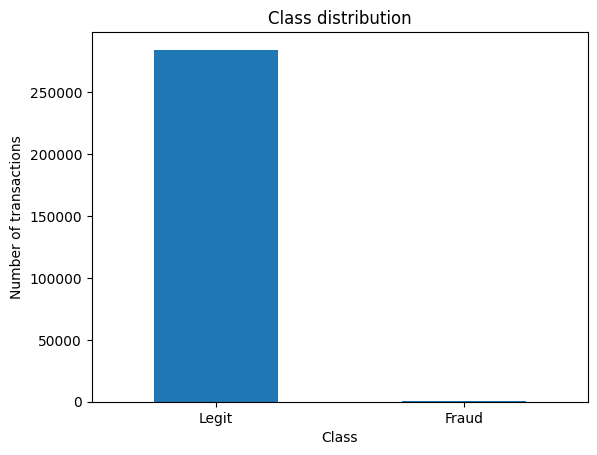

In [19]:
df['Class'].value_counts().plot(kind='bar')
plt.title('Class distribution')
plt.xticks([0,1],['Legit', 'Fraud'], rotation=0)
plt.ylabel('Number of transactions')
plt.show()

In [20]:
print(df['Amount'].describe())
print(df.groupby('Class')['Amount'].describe())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


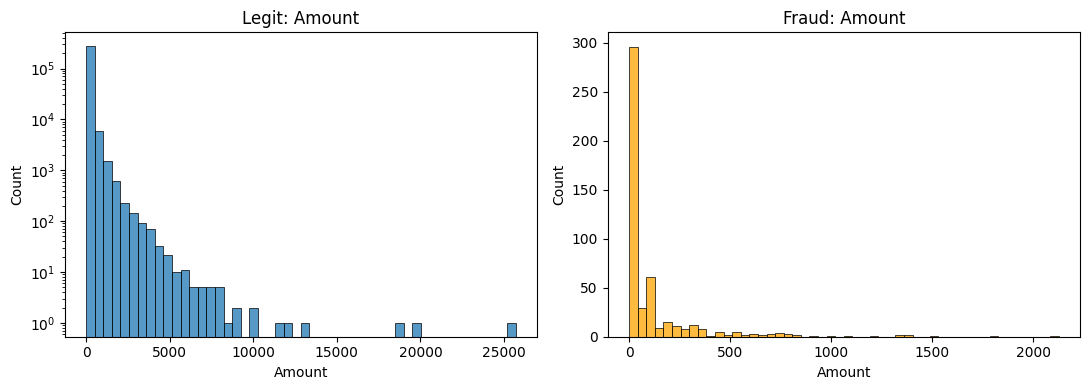

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[df['Class']==0]['Amount'], bins=50, ax=axes[0])
axes[0].set_title('Legit: Amount'); axes[0].set_yscale('log')
sns.histplot(df[df['Class']==1]['Amount'], bins=50, color='orange', ax=axes[1])
axes[1].set_title('Fraud: Amount')
plt.tight_layout(); plt.show()

47.99777777777778 hours


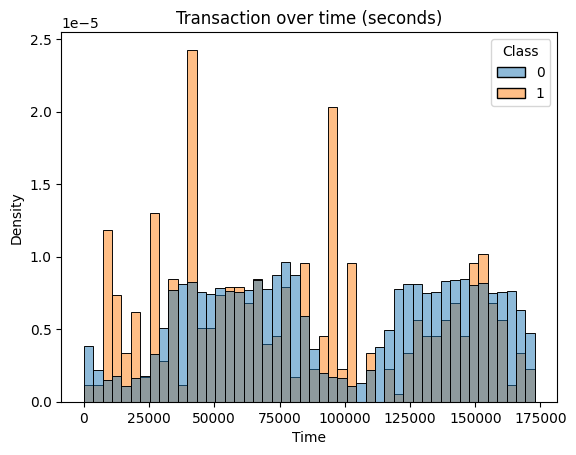

In [22]:
print(df['Time'].max() / 3600, "hours")
sns.histplot(data=df, x='Time', hue='Class', bins=48, stat='density',common_norm=False)
plt.title('Transaction over time (seconds)')
plt.show()

In [23]:
corr = df.corr()['Class'].drop('Class').sort_values()
print(corr.head(5))  # most negative
print(corr.tail(5))  # most positive

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


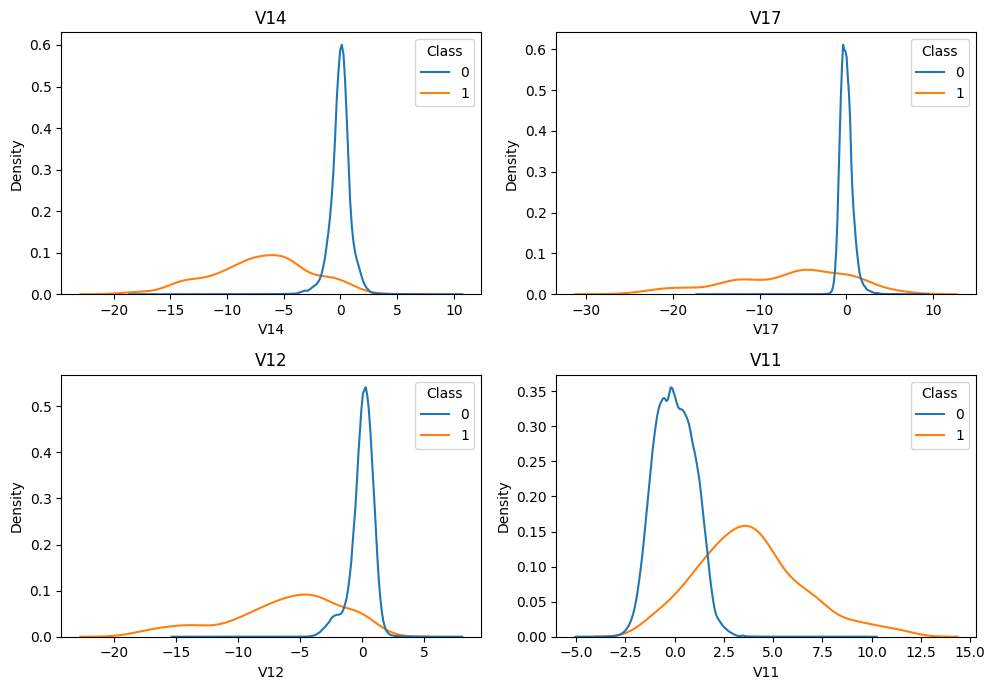

In [24]:
top = ['V14', 'V17', 'V12', 'V11']
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flatten(), top):
    sns.kdeplot(data=df, x=col, hue='Class', common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(y_train.value_counts())
print(y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [26]:
from sklearn.preprocessing import RobustScaler

X_train = X_train.copy()
X_test = X_test.copy()

scaler = RobustScaler()
scaler.fit(X_train)
X_train[['Amount', 'Time']] = scaler.fit_transform(X_train[['Amount', 'Time']])
X_test[['Amount', 'Time']] = scaler.transform(X_test[['Amount', 'Time']])

In [27]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_sm.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    227451
1    227451
Name: count, dtype: int64


In [28]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix)

results = []

def evaluate(name, model, X_te, y_te):
    proba = model.predict_proba(X_te)[:, 1]   # probability of fraud
    pred = (proba >= 0.5).astype(int)         # default cut-off
    print(name)
    print(confusion_matrix(y_te, pred))
    results.append({
        'Model': name,
        'Precision': precision_score(y_te, pred),
        'Recall': recall_score(y_te, pred),
        'F1': f1_score(y_te, pred),
        'ROC-AUC': roc_auc_score(y_te, proba),
        'PR-AUC': average_precision_score(y_te, proba),
    })

In [29]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sm, y_train_sm)
evaluate('LogReg + SMOTE', lr, X_test, y_test)

LogReg + SMOTE
[[55425  1439]
 [    8    90]]


In [30]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_train_sm, y_train_sm)
evaluate('RandomForest + SMOTE', rf, X_test, y_test)

RandomForest + SMOTE
[[56849    15]
 [   16    82]]


In [31]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    eval_metric='logloss', n_jobs=-1, random_state=42)
xgb.fit(X_train_sm, y_train_sm)
evaluate('XGBoost + SMOTE', xgb, X_test, y_test)

XGBoost + SMOTE
[[56834    30]
 [   14    84]]


In [32]:
pd.DataFrame(results).round(4)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LogReg + SMOTE,0.0589,0.9184,0.1106,0.9712,0.7251
1,RandomForest + SMOTE,0.8454,0.8367,0.8410,0.9734,0.8704
2,XGBoost + SMOTE,0.7368,0.8571,0.7925,0.9803,0.8707


In [33]:
# How imbalanced is training data? (used by XGBoost)
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(ratio)   # about 577

# 1. LogReg with class weights
lr_w = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_w.fit(X_train, y_train)
evaluate('LogReg + class_weight', lr_w, X_test, y_test)

# 2. Random Forest with class weights
rf_w = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                              n_jobs=-1, random_state=42)
rf_w.fit(X_train, y_train)
evaluate('RandomForest + class_weight', rf_w, X_test, y_test)

# 3. XGBoost with scale_pos_weight
xgb_w = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                      scale_pos_weight=ratio, eval_metric='logloss',
                      n_jobs=-1, random_state=42)
xgb_w.fit(X_train, y_train)
evaluate('XGBoost + scale_pos_weight', xgb_w, X_test, y_test)

# 4. XGBoost with NO imbalance handling at all (the control)
xgb_plain = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          eval_metric='logloss', n_jobs=-1, random_state=42)
xgb_plain.fit(X_train, y_train)
evaluate('XGBoost plain (no handling)', xgb_plain, X_test, y_test)

pd.DataFrame(results).round(4)

577.2868020304569
LogReg + class_weight
[[55476  1388]
 [    8    90]]
RandomForest + class_weight
[[56861     3]
 [   26    72]]
XGBoost + scale_pos_weight
[[56854    10]
 [   15    83]]
XGBoost plain (no handling)
[[56859     5]
 [   20    78]]


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LogReg + SMOTE,0.0589,0.9184,0.1106,0.9712,0.7251
1,RandomForest + SMOTE,0.8454,0.8367,0.8410,0.9734,0.8704
2,XGBoost + SMOTE,0.7368,0.8571,0.7925,0.9803,0.8707
3,LogReg + class_weight,0.0609,0.9184,0.1142,0.9720,0.7175
4,RandomForest + class_weight,0.9600,0.7347,0.8324,0.9478,0.8597
5,XGBoost + scale_pos_weight,0.8925,0.8469,0.8691,0.9673,0.8852
6,XGBoost plain (no handling),0.9398,0.7959,0.8619,0.9628,0.8485


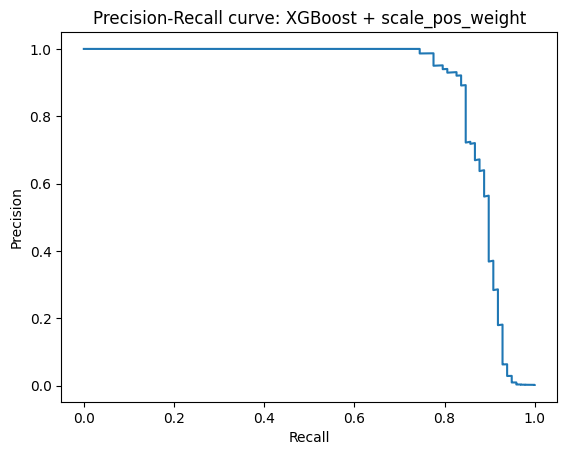

0.1 precision 0.822 recall 0.847 flagged 101
0.3 precision 0.874 recall 0.847 flagged 95
0.5 precision 0.892 recall 0.847 flagged 93
0.7 precision 0.891 recall 0.837 flagged 92
0.9 precision 0.931 recall 0.827 flagged 87


In [34]:
from sklearn.metrics import precision_recall_curve

proba = xgb_w.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

plt.plot(rec, prec)
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall curve: XGBoost + scale_pos_weight')
plt.show()

# Try several cut-offs
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (proba >= t).astype(int)
    print(t, 'precision', round(precision_score(y_test, pred), 3),
             'recall', round(recall_score(y_test, pred), 3),
             'flagged', pred.sum())

0.001 caught 90 false alarms 317 recall 0.918
0.005 caught 88 false alarms 110 recall 0.898
0.01 caught 87 false alarms 65 recall 0.888
0.02 caught 86 false alarms 42 recall 0.878
0.05 caught 83 false alarms 27 recall 0.847
0.1 caught 83 false alarms 18 recall 0.847


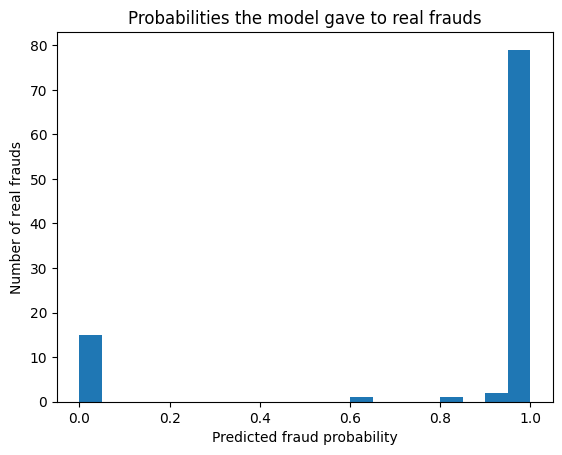

In [35]:
y_arr = y_test.values
for t in [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]:
    pred = (proba >= t).astype(int)
    tp = ((pred == 1) & (y_arr == 1)).sum()
    fp = ((pred == 1) & (y_arr == 0)).sum()
    print(t, 'caught', tp, 'false alarms', fp, 'recall', round(tp / 98, 3))

# Where do the 98 real frauds sit on the probability scale?
plt.hist(proba[y_arr == 1], bins=20)
plt.xlabel('Predicted fraud probability'); plt.ylabel('Number of real frauds')
plt.title('Probabilities the model gave to real frauds')
plt.show()

In [36]:
risk = proba * 100

bands = pd.cut(proba, bins=[0, 0.02, 0.5, 1.01], labels=['Low', 'Medium', 'High'], right=False)

summary = (pd.DataFrame({'band': bands, 'is_fraud': y_arr})
           .groupby('band', observed=True)['is_fraud']
           .agg(transactions='count', frauds='sum'))
summary['fraud_rate_%'] = (summary['frauds'] / summary['transactions'] * 100).round(2)
print(summary)

        transactions  frauds  fraud_rate_%
band                                      
Low            56834      12          0.02
Medium            35       3          8.57
High              93      83         89.25


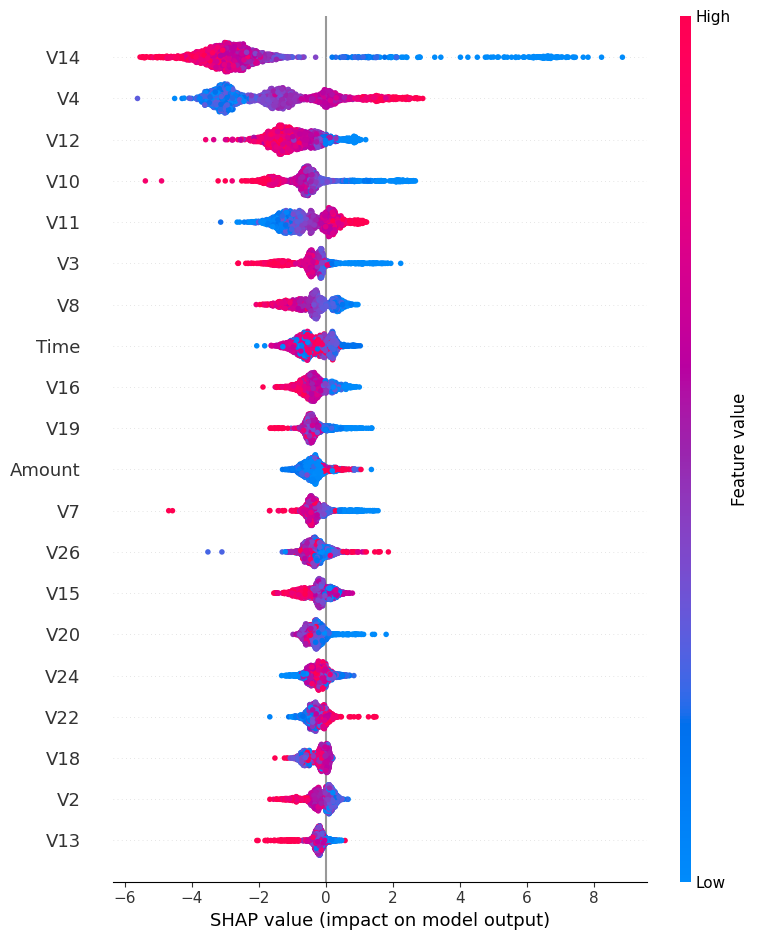

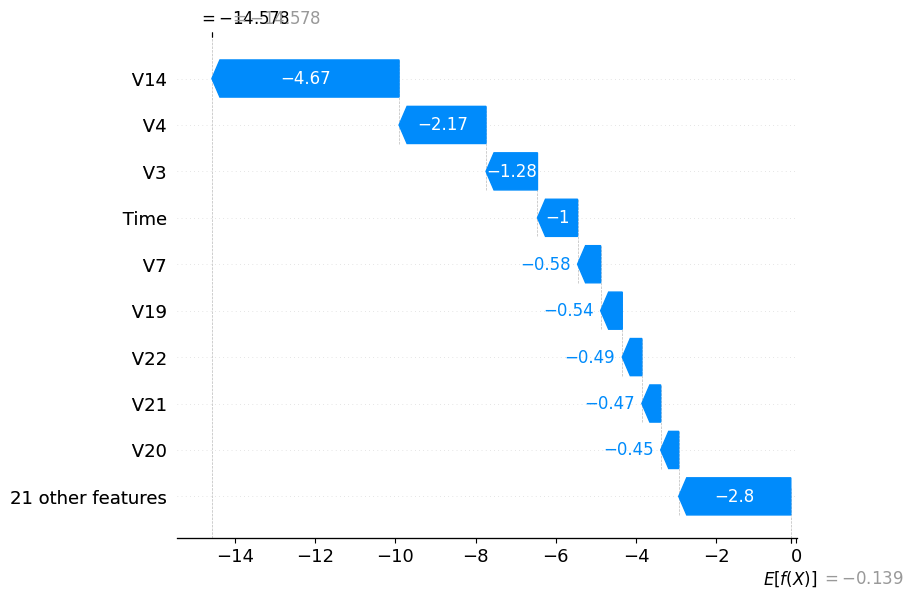

[23 30 34 35 39 45 51 56 66 90 94 95]


In [37]:
# run once if needed: !pip install shap
import shap

explainer = shap.TreeExplainer(xgb_w)

# Use a sample for speed: all test frauds plus 2000 random legit
rng = np.random.RandomState(42)
legit_idx = rng.choice(np.where(y_arr == 0)[0], 2000, replace=False)
fraud_idx = np.where(y_arr == 1)[0]
idx = np.concatenate([fraud_idx, legit_idx])

X_sample = X_test.iloc[idx]
shap_values = explainer.shap_values(X_sample)

# 1. Global view: which features matter most, and in which direction
shap.summary_plot(shap_values, X_sample)

# 2. Local view: why was ONE fraud flagged?
# a legit transaction (index in the sample after the 98 frauds)
shap.plots._waterfall.waterfall_legacy(explainer.expected_value, shap_values[200],
                                       X_sample.iloc[200], max_display=10)

# a fraud the model gave a low score (find it first)
sample_proba = xgb_w.predict_proba(X_sample)[:, 1]
missed = np.where((np.arange(len(X_sample)) < 98) & (sample_proba < 0.02))[0]
print(missed)

In [38]:
import joblib
joblib.dump(xgb_w, 'fraud_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X_train.columns), 'feature_names.pkl')

['feature_names.pkl']

In [39]:
import sklearn, xgboost, shap
print(sklearn.__version__, xgboost.__version__, shap.__version__)

1.6.1 3.4.1 0.54.1


In [40]:
raw_test = df.loc[X_test.index]            # original, unscaled rows
fraud_rows = raw_test[raw_test['Class'] == 1]                    # all 98 frauds
legit_rows = raw_test[raw_test['Class'] == 0].sample(300, random_state=42)
sample = pd.concat([fraud_rows, legit_rows]).sample(frac=1, random_state=42)
sample.to_csv('sample_transactions.csv', index=False)
print(sample.shape)   # should be (398, 31)

(398, 31)


In [41]:
xgb_w.save_model('fraud_model.json')